In [18]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [19]:
!pip -q install pandas scikit-learn matplotlib

In [20]:
import ast
import io
import re
import tokenize
import os
from datetime import datetime

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("ACVAA environment is ready.")

ACVAA environment is ready.


In [21]:
os.makedirs("sample_data", exist_ok=True)
os.makedirs("results", exist_ok=True)

print("Project folders created.")

Project folders created.


In [22]:
baseline_1 = """
def calculate_total(price, quantity):
    total = price * quantity
    return total

price = 100
quantity = 3
print(calculate_total(price, quantity))
"""

baseline_2 = """
def calculate_discount(amount, rate):
    discount = amount * rate
    return discount

amount = 500
rate = 0.10
print(calculate_discount(amount, rate))
"""

with open("sample_data/baseline_1.py", "w") as file:
    file.write(baseline_1)

with open("sample_data/baseline_2.py", "w") as file:
    file.write(baseline_2)

print("Baseline files created.")

Baseline files created.


In [24]:
submission = """
def final_amount(cost, number):
    result = cost * number
    return result

cost = 100
number = 3
print(final_amount(cost, number))
"""

with open("sample_data/submission.py", "w") as file:
    file.write(submission)

submission_filename = "sample_data/submission.py"

print("Demo submission created.")

Demo submission created.


In [25]:
def read_code(filename):
    with open(filename, "r", encoding="utf-8", errors="ignore") as file:
        return file.read()


baseline_1_code = read_code("sample_data/baseline_1.py")
baseline_2_code = read_code("sample_data/baseline_2.py")
submission_code = read_code(submission_filename)

print("Submission loaded successfully.")
print(submission_code)

Submission loaded successfully.

def final_amount(cost, number):
    result = cost * number
    return result

cost = 100
number = 3
print(final_amount(cost, number))



In [26]:
def normalize_code(code):
    code = re.sub(r"#.*", "", code)
    code = re.sub(r"\b[A-Za-z_][A-Za-z0-9_]*\b", "NAME", code)
    code = re.sub(r"\b\d+(\.\d+)?\b", "NUMBER", code)
    code = re.sub(r"\s+", " ", code)

    return code.strip()


print(normalize_code(submission_code))

NAME NAME(NAME, NAME): NAME = NAME * NAME NAME NAME NAME = NUMBER NAME = NUMBER NAME(NAME(NAME, NAME))


In [27]:
def token_text(code):
    tokens = []

    try:
        stream = io.StringIO(code).readline

        for token in tokenize.generate_tokens(stream):
            if token.type in {
                tokenize.NAME,
                tokenize.NUMBER,
                tokenize.STRING,
                tokenize.OP,
            }:
                tokens.append(token.string)

    except tokenize.TokenError:
        pass

    return " ".join(tokens)


print(token_text(submission_code))

def final_amount ( cost , number ) : result = cost * number return result cost = 100 number = 3 print ( final_amount ( cost , number ) )


In [28]:
def ast_features(code):
    try:
        tree = ast.parse(code)

    except SyntaxError:
        return {
            "Lines": len(code.splitlines()),
            "Functions": 0,
            "Loops": 0,
            "Conditions": 0,
            "Imports": 0,
            "AST nodes": 0,
            "Syntax error": 1,
        }

    nodes = list(ast.walk(tree))

    return {
        "Lines": len(code.splitlines()),
        "Functions": sum(
            isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
            for node in nodes
        ),
        "Loops": sum(
            isinstance(node, (ast.For, ast.While))
            for node in nodes
        ),
        "Conditions": sum(
            isinstance(node, ast.If)
            for node in nodes
        ),
        "Imports": sum(
            isinstance(node, (ast.Import, ast.ImportFrom))
            for node in nodes
        ),
        "AST nodes": len(nodes),
        "Syntax error": 0,
    }

In [29]:
submission_features = ast_features(submission_code)

features_table = pd.DataFrame([
    submission_features
])

display(features_table)

,Lines,Functions,Loops,Conditions,Imports,AST nodes,Syntax error
0,8,1,0,0,0,36,0


In [30]:
def token_similarity(code_a, code_b):
    documents = [
        normalize_code(code_a),
        normalize_code(code_b),
    ]

    vectorizer = TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 3)
    )

    matrix = vectorizer.fit_transform(documents)

    score = cosine_similarity(
        matrix[0:1],
        matrix[1:2]
    )[0][0]

    return round(float(score) * 100, 2)

In [31]:
def structural_similarity(code_a, code_b):
    features_a = ast_features(code_a)
    features_b = ast_features(code_b)

    keys = [
        "Lines",
        "Functions",
        "Loops",
        "Conditions",
        "Imports",
        "AST nodes",
    ]

    differences = []

    for key in keys:
        value_a = features_a[key]
        value_b = features_b[key]

        denominator = max(abs(value_a), abs(value_b), 1)
        difference = abs(value_a - value_b) / denominator

        differences.append(difference)

    average_difference = sum(differences) / len(differences)

    score = max(0, 100 * (1 - average_difference))

    return round(score, 2)

In [32]:
def compare_codes(code_a, code_b):
    token_score = token_similarity(code_a, code_b)
    structure_score = structural_similarity(code_a, code_b)

    combined_score = (
        token_score * 0.6
        + structure_score * 0.4
    )

    return {
        "Token similarity (%)": round(token_score, 2),
        "Structural similarity (%)": round(structure_score, 2),
        "Combined similarity (%)": round(combined_score, 2),
    }

In [33]:
result_1 = compare_codes(
    baseline_1_code,
    submission_code
)

result_2 = compare_codes(
    baseline_2_code,
    submission_code
)

print("Comparison with baseline 1:")
print(result_1)

print()
print("Comparison with baseline 2:")
print(result_2)

Comparison with baseline 1:
{'Token similarity (%)': 100.0, 'Structural similarity (%)': 100.0, 'Combined similarity (%)': 100.0}

Comparison with baseline 2:
{'Token similarity (%)': 100.0, 'Structural similarity (%)': 100.0, 'Combined similarity (%)': 100.0}


In [34]:
results = pd.DataFrame([
    {
        "Baseline": "baseline_1.py",
        **result_1
    },
    {
        "Baseline": "baseline_2.py",
        **result_2
    }
])

display(results)

,Baseline,Token similarity (%),Structural similarity (%),Combined similarity (%)
0,baseline_1.py,100.0,100.0,100.0
1,baseline_2.py,100.0,100.0,100.0


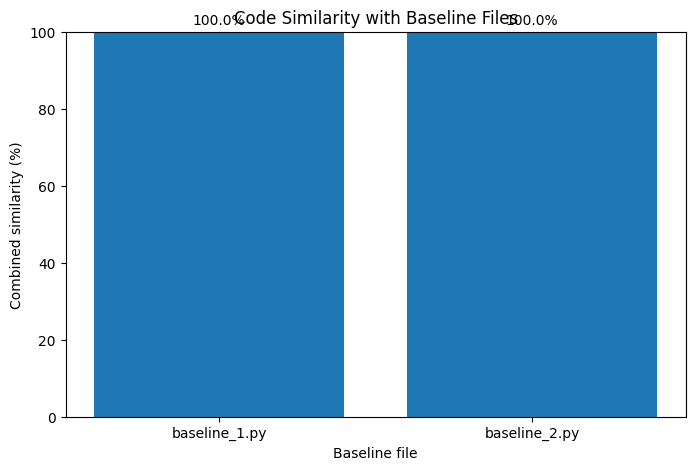

In [35]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Baseline"],
    results["Combined similarity (%)"]
)

plt.title("Code Similarity with Baseline Files")
plt.xlabel("Baseline file")
plt.ylabel("Combined similarity (%)")
plt.ylim(0, 100)

for index, value in enumerate(
    results["Combined similarity (%)"]
):
    plt.text(
        index,
        value + 2,
        f"{value}%",
        ha="center"
    )

plt.show()

In [36]:
highest_similarity = results[
    "Combined similarity (%)"
].max()

if highest_similarity >= 70:
    recommendation = (
        "High similarity — instructor review recommended."
    )

elif highest_similarity >= 40:
    recommendation = (
        "Moderate similarity — review if necessary."
    )

else:
    recommendation = (
        "Low similarity — no major similarity detected."
    )

print(f"Highest similarity: {highest_similarity}%")
print(recommendation)

Highest similarity: 100.0%
High similarity — instructor review recommended.


In [37]:
def generate_viva_questions(code):
    questions = []

    try:
        tree = ast.parse(code)

    except SyntaxError:
        return [
            "Where is the syntax error?",
            "How would you correct the syntax error?",
            "What is the purpose of this program?",
            "What output should the program produce?",
        ]

    nodes = list(ast.walk(tree))

    if any(isinstance(node, ast.For) for node in nodes):
        questions.append(
            "Explain what the for-loop does."
        )

    if any(isinstance(node, ast.While) for node in nodes):
        questions.append(
            "What condition stops the while-loop?"
        )

    if any(isinstance(node, ast.If) for node in nodes):
        questions.append(
            "What happens if the if-condition is false?"
        )

    functions = [
        node.name
        for node in nodes
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef))
    ]

    if functions:
        questions.append(
            f"What is the purpose of the function '{functions[0]}'?"
        )

    if any(isinstance(node, ast.List) for node in nodes):
        questions.append(
            "What happens if the list is empty?"
        )

    if any(isinstance(node, ast.Import) for node in nodes):
        questions.append(
            "Why is the imported module needed?"
        )

    questions.append(
        "Choose one line and explain what happens if it is changed."
    )

    unique_questions = []

    for question in questions:
        if question not in unique_questions:
            unique_questions.append(question)

    return unique_questions[:4]

In [38]:
viva_questions = generate_viva_questions(submission_code)

print("Generated Code Viva Questions")
print("-----------------------------")

for number, question in enumerate(
    viva_questions,
    start=1
):
    print(f"{number}. {question}")

Generated Code Viva Questions
-----------------------------
1. What is the purpose of the function 'final_amount'?
2. Choose one line and explain what happens if it is changed.


In [39]:
viva_scores = []

print("Enter a score from 0 to 3 for each answer.")

for number, question in enumerate(
    viva_questions,
    start=1
):
    print()
    print(f"Question {number}: {question}")

    while True:
        try:
            score = int(input("Enter score: "))

            if score in [0, 1, 2, 3]:
                viva_scores.append(score)
                break

            print("Please enter only 0, 1, 2, or 3.")

        except ValueError:
            print("Please enter a number.")

Enter a score from 0 to 3 for each answer.

Question 1: What is the purpose of the function 'final_amount'?
Enter score: 2

Question 2: Choose one line and explain what happens if it is changed.
Enter score: 1


In [40]:
understanding_score = (
    sum(viva_scores) / (len(viva_scores) * 3)
) * 100

understanding_score = round(
    understanding_score,
    2
)

if understanding_score >= 70:
    understanding_label = "Strong understanding"

elif understanding_score >= 40:
    understanding_label = "Partial understanding"

else:
    understanding_label = "Limited understanding"

print(f"Understanding score: {understanding_score}%")
print(understanding_label)

Understanding score: 50.0%
Partial understanding


In [41]:
final_report = pd.DataFrame([
    {
        "Submission file": submission_filename,
        "Highest similarity (%)": highest_similarity,
        "Understanding score (%)": understanding_score,
        "Understanding level": understanding_label,
        "Recommendation": recommendation,
        "Important note": (
            "This system does not prove plagiarism or AI usage. "
            "Human instructor review is required."
        ),
        "Generated at": datetime.now().strftime(
            "%Y-%m-%d %H:%M:%S"
        )
    }
])

display(final_report)

,Submission file,Highest similarity (%),Understanding score (%),Understanding level,Recommendation,Important note,Generated at
0,sample_data/submission.py,100.0,50.0,Partial understanding,High similarity — instructor review recommended.,This system does not prove plagiarism or AI us...,2026-10-12 05:50:09


In [42]:
final_report.to_csv(
    "results/ACVAA_final_report.csv",
    index=False
)

results.to_csv(
    "results/code_similarity_results.csv",
    index=False
)

print("Reports saved in the results folder.")

Reports saved in the results folder.


In [43]:
requirements_text = """pandas
scikit-learn
matplotlib
"""

with open("requirements.txt", "w") as file:
    file.write(requirements_text)

print(requirements_text)

pandas
scikit-learn
matplotlib



In [44]:
readme_text = """# ACVAA: AI Code Viva & Authorship Analyzer

ACVAA is an educational research prototype for comparing Python programming
assignments and supporting student understanding assessment through code-specific
viva questions.

## Main Features

- Normalized Python code comparison.
- Token-based similarity.
- AST-based structural similarity.
- Explainable similarity results.
- Automatically generated code viva questions.
- Human-entered understanding score.
- CSV report generation.

## Workflow

1. Load baseline Python files.
2. Upload a new Python submission.
3. Normalize and analyze the code.
4. Calculate token similarity.
5. Calculate structural similarity.
6. Generate viva questions.
7. Record an understanding score.
8. Produce a final report.

## Technologies

- Python
- Google Colab
- Pandas
- Scikit-learn
- Matplotlib
- Python AST
- Tokenization

## Limitations

This project does not prove plagiarism, cheating, or AI usage. It provides
supporting evidence for instructor review. Final academic decisions should be
made by a human teacher.

## Future Work

- Larger student dataset.
- Git process analysis.
- Semantic code comparison.
- Support for Java, C++, and JavaScript.
- Automated speech-based viva.
- Fairness and false-positive evaluation.

## Author

Sharmeen Mahmood
"""

with open("README.md", "w") as file:
    file.write(readme_text)

print("README.md created.")

README.md created.


In [45]:
print("Project files:")
print()

for root, directories, filenames in os.walk("."):
    if ".config" in root:
        continue

    for filename in filenames:
        path = os.path.join(root, filename)

        if path.startswith("./."):
            continue

        print(path)

Project files:

./viva.py
./streamlit.log
./baseline_2.py
./submission.py
./README.md
./baseline_1.py
./requirements.txt
./analyzer.py
./app.py
./sample_data/anscombe.json
./sample_data/README.md
./sample_data/baseline_2.py
./sample_data/submission.py
./sample_data/baseline_1.py
./sample_data/mnist_train_small.csv
./sample_data/mnist_test.csv
./sample_data/california_housing_train.csv
./sample_data/california_housing_test.csv
./drive/MyDrive/matric degree.jpeg
./drive/MyDrive/pic.jpg
./drive/MyDrive/dd.csv
./drive/MyDrive/processed.csv
./drive/MyDrive/dev.csv
./drive/MyDrive/test.csv
./drive/MyDrive/imbalance_strategy.json
./drive/MyDrive/best_params.json
./drive/MyDrive/final_metrics.csv
./drive/MyDrive/mcnemar_results.csv
./drive/MyDrive/calibration_curve.png
./drive/MyDrive/shap_summary_plot.png
./drive/MyDrive/shap_dependence_plots.png
./drive/MyDrive/shap_waterfall_ulcer_case.png
./drive/MyDrive/shap_waterfall_no_ulcer_case.png
./drive/MyDrive/Analysis_updated.ipynb
./drive/MyDriv

In [46]:
!zip -r ACVAA_GitHub_Project.zip \
    README.md \
    requirements.txt \
    sample_data \
    results

  adding: README.md (deflated 47%)
  adding: requirements.txt (stored 0%)
  adding: sample_data/ (stored 0%)
  adding: sample_data/anscombe.json (deflated 83%)
  adding: sample_data/README.md (deflated 39%)
  adding: sample_data/baseline_2.py (deflated 43%)
  adding: sample_data/submission.py (deflated 37%)
  adding: sample_data/baseline_1.py (deflated 42%)
  adding: sample_data/mnist_train_small.csv (deflated 88%)
  adding: sample_data/mnist_test.csv (deflated 88%)
  adding: sample_data/california_housing_train.csv (deflated 79%)
  adding: sample_data/california_housing_test.csv (deflated 76%)
  adding: results/ (stored 0%)
  adding: results/ACVAA_final_report.csv (deflated 33%)
  adding: results/code_similarity_results.csv (deflated 48%)
